In [ ]:
!pip install -q kagglehub matplotlib seaborn pandas numpy

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

pd.set_option("display.max_columns", None)

dataset_path = kagglehub.dataset_download("jsphyg/weather-dataset-rattle-package")

print("Dataset téléchargé dans :", dataset_path)
print("Fichiers disponibles :", os.listdir(dataset_path))

csv_path = os.path.join(dataset_path, "weatherAUS.csv")

try:
    df = pd.read_csv(csv_path)
except UnicodeDecodeError:
    df = pd.read_csv(csv_path, encoding="latin1")

print("Dimensions du dataset :", df.shape)
display(df.head())
df.info()

100%|██████████| 3.83M/3.83M [00:00<00:00, 5.87MB/s]

Extracting files...


Dataset téléchargé dans : C:\Users\arthu\.cache\kagglehub\datasets\jsphyg\weather-dataset-rattle-package\versions\2
Fichiers disponibles : ['weatherAUS.csv']
Dimensions du dataset : (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


In [9]:
df_eda = df.copy()

df_eda["Date"] = pd.to_datetime(df_eda["Date"])

print("Taille dataset :", df_eda.shape)
print("\nColonnes :")
print(df_eda.columns.tolist())

print("\nNbr localisations :", df_eda["Location"].nunique())
print("Nbr dates uniques :", df_eda["Date"].nunique())
print("Période observé :", df_eda["Date"].min(), "au", df_eda["Date"].max())

print("\nDoublons :", df_eda.duplicated().sum())

Taille dataset : (145460, 23)

Colonnes :
['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']

Nbr localisations : 49
Nbr dates uniques : 3436
Période observé : 2007-11-01 00:00:00 au 2017-06-25 00:00:00

Doublons : 0


In [11]:
df_eda.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,145460,2013-04-04 21:08:51.907053,2007-11-01 00:00:00,2011-01-11 00:00:00,2013-06-02 00:00:00,2015-06-14 00:00:00,2017-06-25 00:00:00,NaN
MinTemp,143975.0,12.194034,-8.5,7.6,12.0,16.9,33.9,6.398495
MaxTemp,144199.0,23.221348,-4.8,17.9,22.6,28.2,48.1,7.119049
Rainfall,142199.0,2.360918,0.0,0.0,0.0,0.8,371.0,8.47806
Evaporation,82670.0,5.468232,0.0,2.6,4.8,7.4,145.0,4.193704
Sunshine,75625.0,7.611178,0.0,4.8,8.4,10.6,14.5,3.785483
WindGustSpeed,135197.0,40.03523,6.0,31.0,39.0,48.0,135.0,13.607062
WindSpeed9am,143693.0,14.043426,0.0,7.0,13.0,19.0,130.0,8.915375
WindSpeed3pm,142398.0,18.662657,0.0,13.0,19.0,24.0,87.0,8.8098
Humidity9am,142806.0,68.880831,0.0,57.0,70.0,83.0,100.0,19.029164


In [14]:
missing_count = df_eda.isna().sum().sort_values(ascending=False)
missing_percent = (df_eda.isna().mean() * 100).sort_values(ascending=False)

missing_df = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})

missing_df[missing_df["missing_count"] > 0]

,missing_count,missing_percent
Sunshine,69835,48.009762
Evaporation,62790,43.166506
Cloud3pm,59358,40.807095
Cloud9am,55888,38.421559
Pressure9am,15065,10.356799
Pressure3pm,15028,10.331363
WindDir9am,10566,7.263853
WindGustDir,10326,7.098859
WindGustSpeed,10263,7.055548
Humidity3pm,4507,3.098446


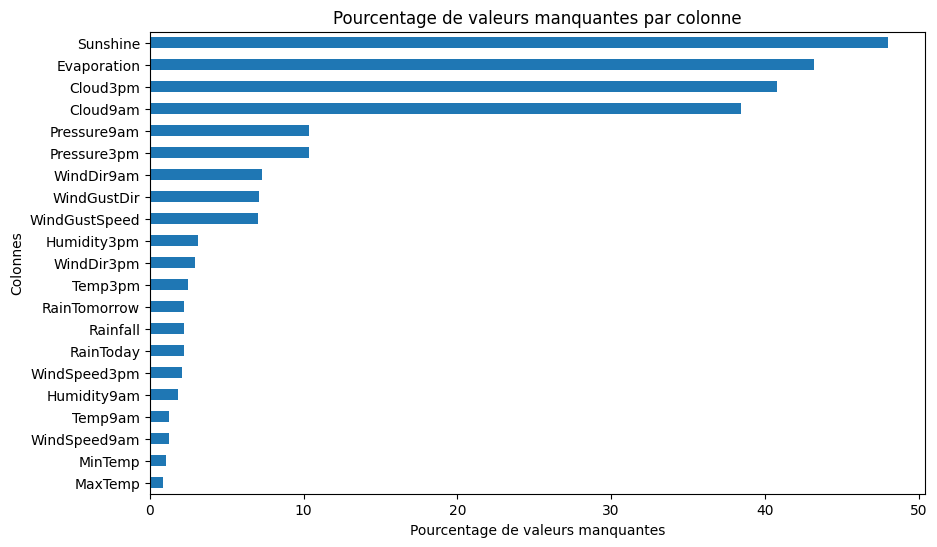

In [15]:
plt.figure(figsize=(10, 6))
missing_percent[missing_percent > 0].sort_values(ascending=True).plot(kind="barh")
plt.title("Pourcentage de valeurs manquantes par colonne")
plt.xlabel("Pourcentage de valeurs manquantes")
plt.ylabel("Colonnes")
plt.show()

In [16]:
print(df_eda["RainTomorrow"].value_counts(dropna=False))
print("\nPourcentages :")
print(df_eda["RainTomorrow"].value_counts(normalize=True, dropna=False) * 100)

RainTomorrow
No     110316
Yes     31877
NaN      3267
Name: count, dtype: int64

Pourcentages :
RainTomorrow
No     75.839406
Yes    21.914616
NaN     2.245978
Name: proportion, dtype: float64


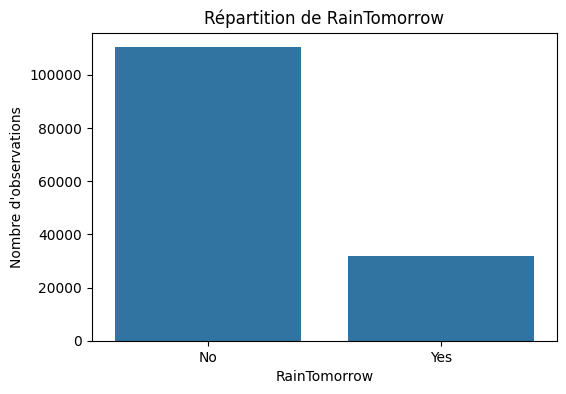

In [18]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_eda, x="RainTomorrow")
plt.title("Répartition de RainTomorrow")
plt.xlabel("RainTomorrow")
plt.ylabel("Nombre d'observations")
plt.show()

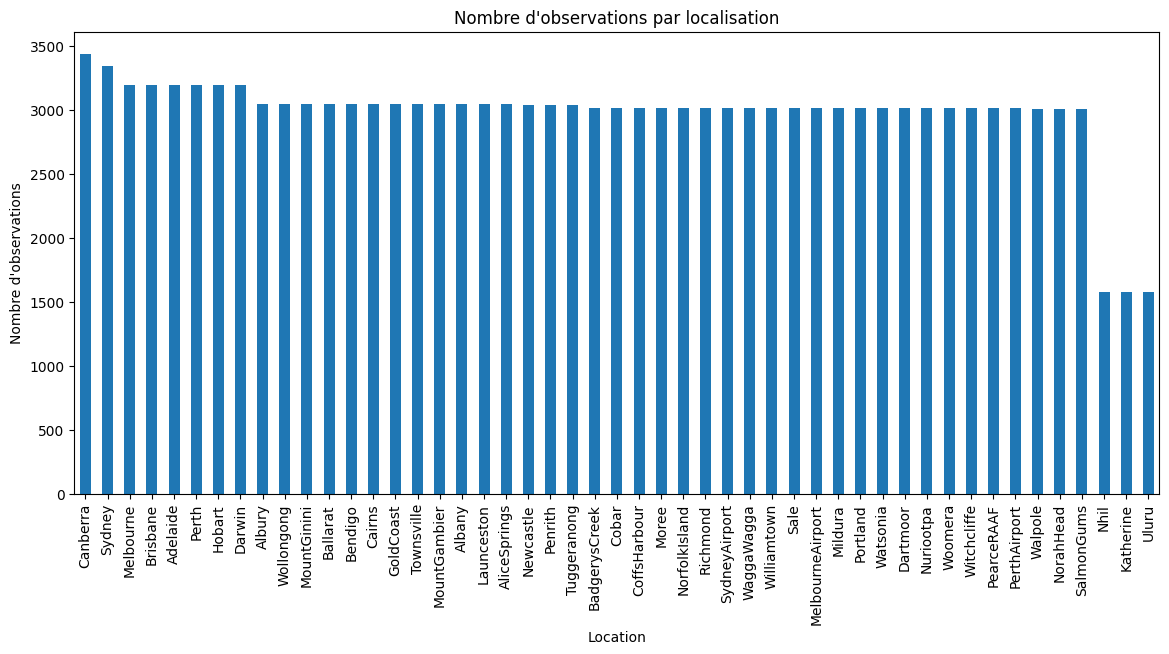

In [19]:
plt.figure(figsize=(14, 6))
df_eda["Location"].value_counts().plot(kind="bar")
plt.title("Nombre d'observations par localisation")
plt.xlabel("Location")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=90)
plt.show()

RainToday
No     110319
Yes     31880
NaN      3261
Name: count, dtype: int64
RainToday
No     75.841468
Yes    21.916678
NaN     2.241853
Name: proportion, dtype: float64


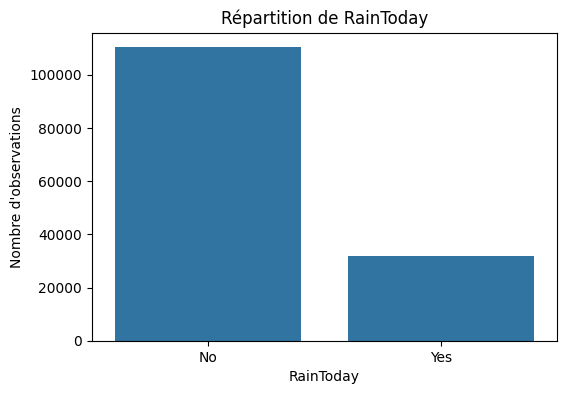

In [20]:
print(df_eda["RainToday"].value_counts(dropna=False))
print(df_eda["RainToday"].value_counts(normalize=True, dropna=False) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df_eda, x="RainToday")
plt.title("Répartition de RainToday")
plt.xlabel("RainToday")
plt.ylabel("Nombre d'observations")
plt.show()

In [21]:
pd.crosstab(
    df_eda["RainToday"],
    df_eda["RainTomorrow"],
    normalize="index"
) * 100

RainTomorrow,No,Yes
RainToday,,
No,84.813229,15.186771
Yes,53.594023,46.405977


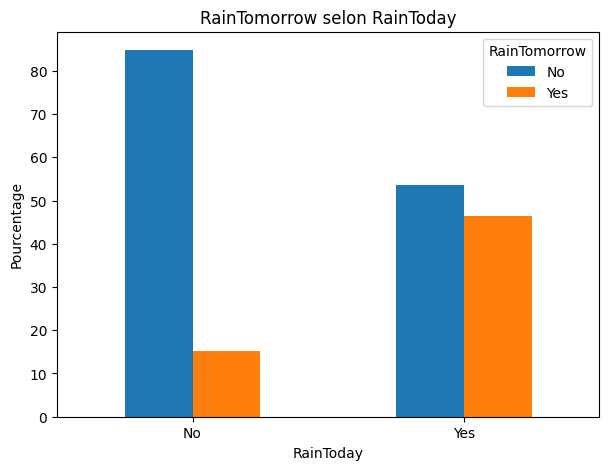

In [22]:
cross_tab = pd.crosstab(df_eda["RainToday"], df_eda["RainTomorrow"], normalize="index") * 100

cross_tab.plot(kind="bar", figsize=(7, 5))
plt.title("RainTomorrow selon RainToday")
plt.xlabel("RainToday")
plt.ylabel("Pourcentage")
plt.xticks(rotation=0)
plt.legend(title="RainTomorrow")
plt.show()

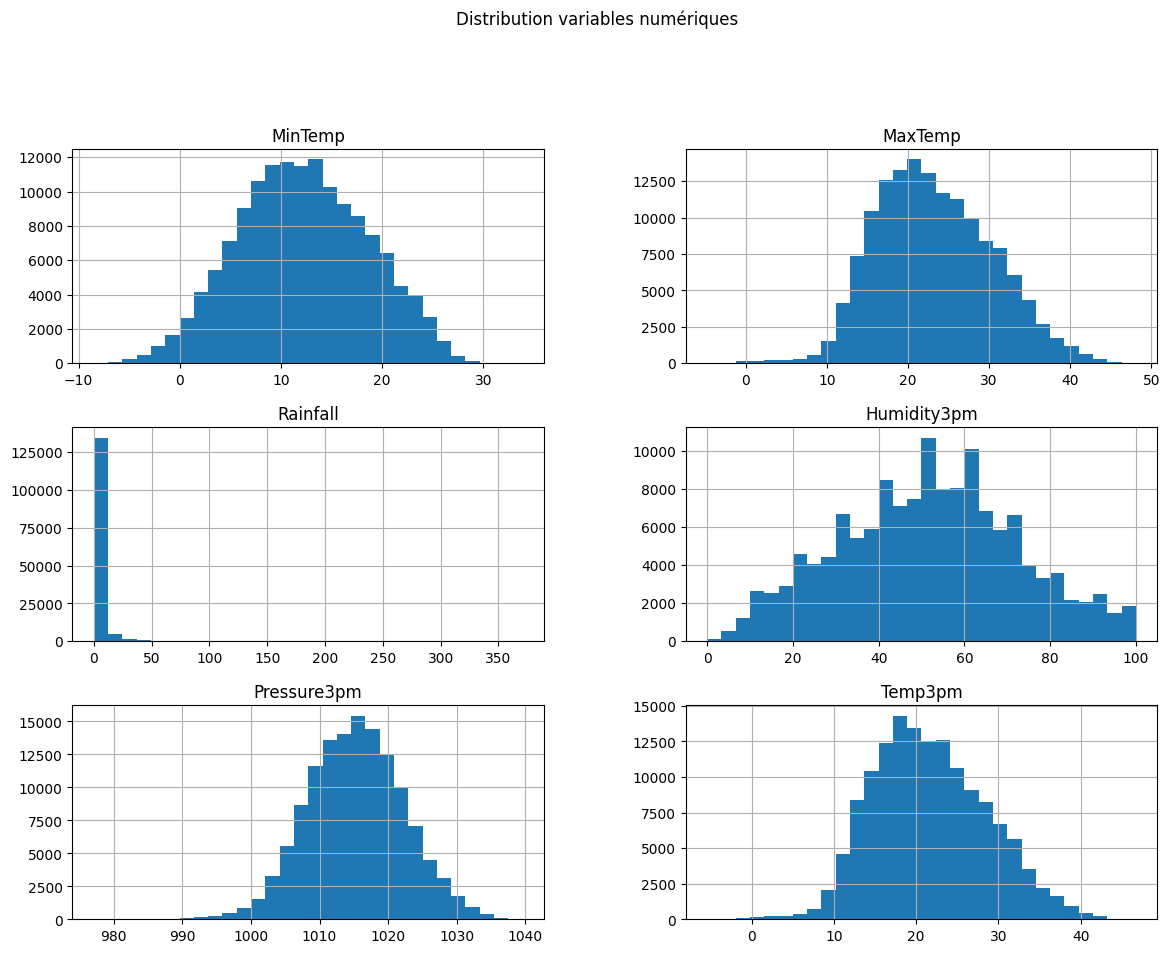

In [24]:
num_cols = ["MinTemp", "MaxTemp", "Rainfall", "Humidity3pm", "Pressure3pm", "Temp3pm"]

df_eda[num_cols].hist(figsize=(14, 10), bins=30)
plt.suptitle("Distribution variables numériques", y=1.02)
plt.show()

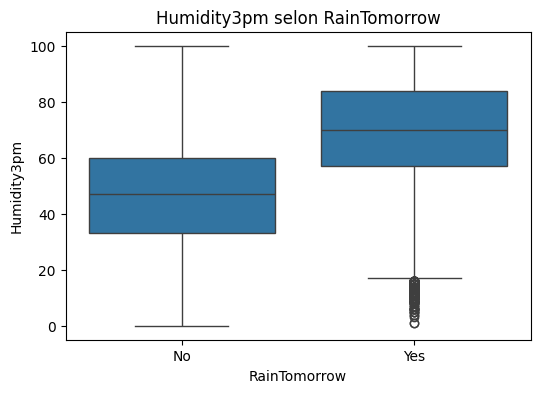

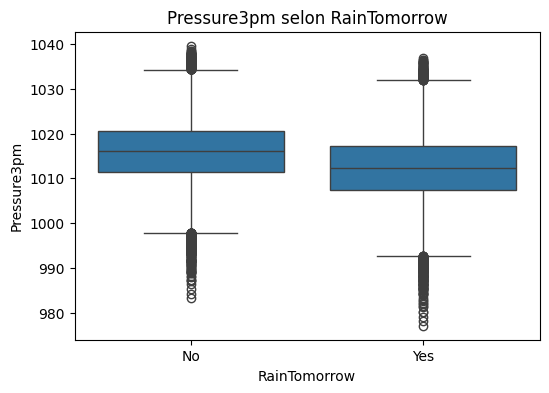

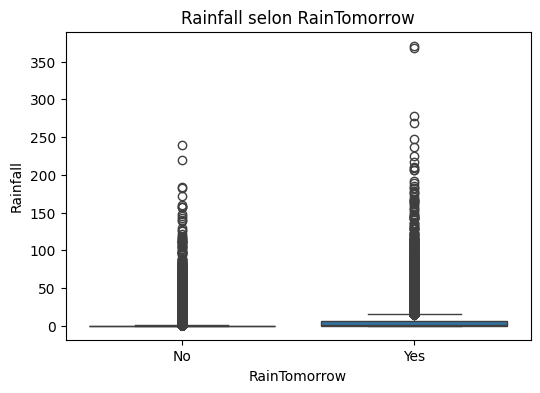

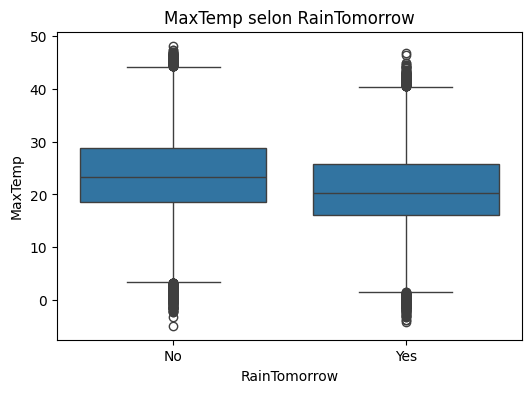

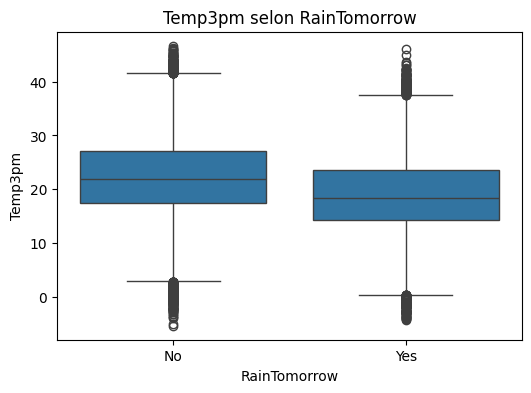

In [25]:
selected_features = ["Humidity3pm", "Pressure3pm", "Rainfall", "MaxTemp", "Temp3pm"]

for col in selected_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_eda, x="RainTomorrow", y=col)
    plt.title(f"{col} selon RainTomorrow")
    plt.show()

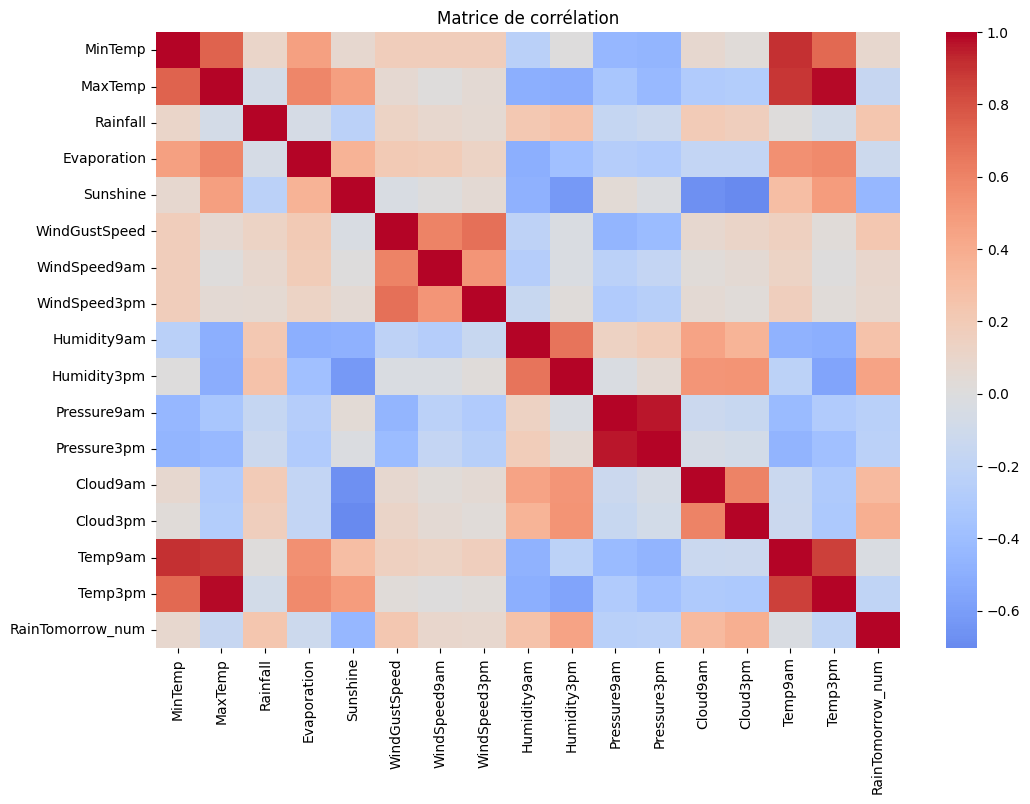

In [26]:
df_corr = df_eda.copy()
df_corr["RainTomorrow_num"] = df_corr["RainTomorrow"].map({"No": 0, "Yes": 1})

corr = df_corr.select_dtypes(include=["number"]).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

In [27]:
corr_target = corr["RainTomorrow_num"].sort_values(ascending=False)
corr_target

RainTomorrow_num    1.000000
Humidity3pm         0.446160
Cloud3pm            0.381870
Cloud9am            0.317380
Humidity9am         0.257161
Rainfall            0.239032
WindGustSpeed       0.234010
WindSpeed9am        0.090995
WindSpeed3pm        0.087817
MinTemp             0.083936
Temp9am            -0.025691
Evaporation        -0.119285
MaxTemp            -0.159237
Temp3pm            -0.192424
Pressure3pm        -0.226031
Pressure9am        -0.246371
Sunshine           -0.450768
Name: RainTomorrow_num, dtype: float64

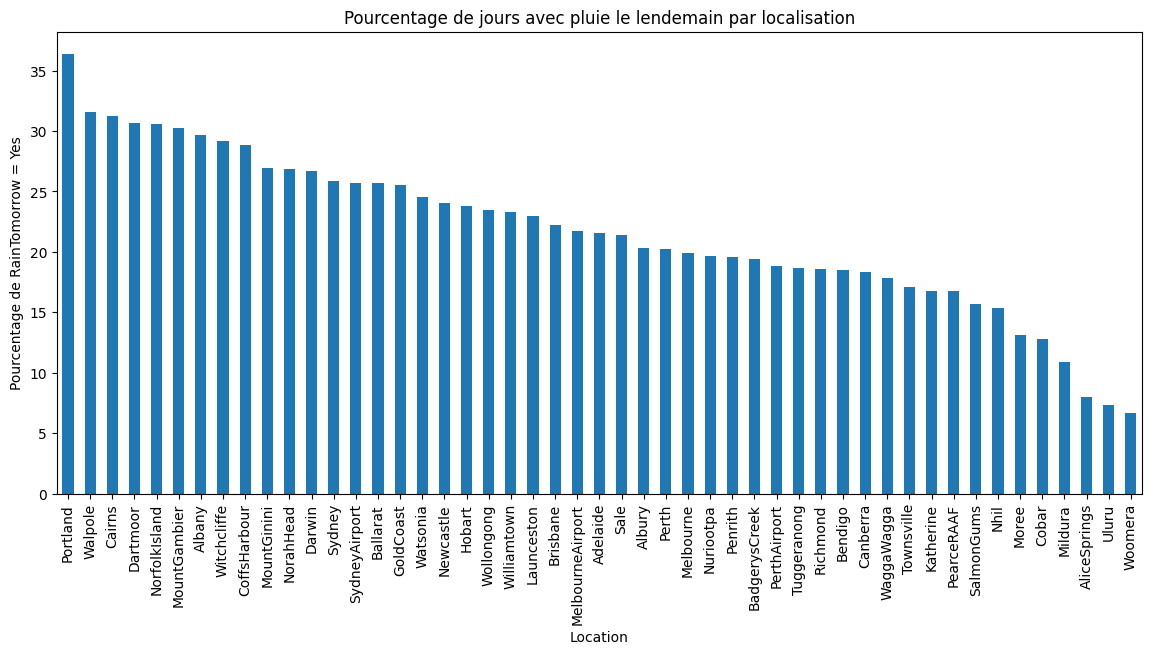

Location
Portland         36.390828
Walpole          31.570193
Cairns           31.250000
Dartmoor         30.641409
NorfolkIsland    30.541708
MountGambier     30.263158
Albany           29.671053
Witchcliffe      29.212363
CoffsHarbour     28.880027
MountGinini      26.940789
Name: RainTomorrow, dtype: float64

In [28]:
rain_by_location = (
    df_eda.groupby("Location")["RainTomorrow"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 6))
rain_by_location.plot(kind="bar")
plt.title("Pourcentage de jours avec pluie le lendemain par localisation")
plt.xlabel("Location")
plt.ylabel("Pourcentage de RainTomorrow = Yes")
plt.xticks(rotation=90)
plt.show()

rain_by_location.head(10)

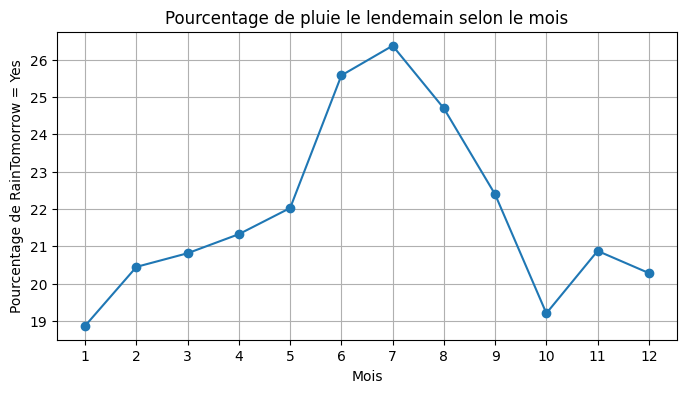

In [29]:
df_eda["Month"] = df_eda["Date"].dt.month

rain_by_month = (
    df_eda.groupby("Month")["RainTomorrow"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

plt.figure(figsize=(8, 4))
rain_by_month.plot(marker="o")
plt.title("Pourcentage de pluie le lendemain selon le mois")
plt.xlabel("Mois")
plt.ylabel("Pourcentage de RainTomorrow = Yes")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [30]:
!pip install -q geopy


[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

In [32]:
locations = sorted(df_eda["Location"].dropna().unique())

query_overrides = {
    "Adelaide": "Adelaide, South Australia, Australia",
    "Albany": "Albany, Western Australia, Australia",
    "Albury": "Albury, New South Wales, Australia",
    "AliceSprings": "Alice Springs, Northern Territory, Australia",
    "BadgerysCreek": "Badgerys Creek, New South Wales, Australia",
    "Ballarat": "Ballarat, Victoria, Australia",
    "Bendigo": "Bendigo, Victoria, Australia",
    "Brisbane": "Brisbane, Queensland, Australia",
    "Cairns": "Cairns, Queensland, Australia",
    "Canberra": "Canberra, Australian Capital Territory, Australia",
    "Cobar": "Cobar, New South Wales, Australia",
    "CoffsHarbour": "Coffs Harbour, New South Wales, Australia",
    "Dartmoor": "Dartmoor, Victoria, Australia",
    "Darwin": "Darwin, Northern Territory, Australia",
    "GoldCoast": "Gold Coast, Queensland, Australia",
    "Hobart": "Hobart, Tasmania, Australia",
    "Katherine": "Katherine, Northern Territory, Australia",
    "Launceston": "Launceston, Tasmania, Australia",
    "Melbourne": "Melbourne, Victoria, Australia",
    "MelbourneAirport": "Melbourne Airport, Victoria, Australia",
    "Mildura": "Mildura, Victoria, Australia",
    "Moree": "Moree, New South Wales, Australia",
    "MountGambier": "Mount Gambier, South Australia, Australia",
    "MountGinini": "Mount Ginini, Australian Capital Territory, Australia",
    "Newcastle": "Newcastle, New South Wales, Australia",
    "Nhil": "Nhill, Victoria, Australia",
    "NorahHead": "Norah Head, New South Wales, Australia",
    "NorfolkIsland": "Norfolk Island, Australia",
    "Nuriootpa": "Nuriootpa, South Australia, Australia",
    "PearceRAAF": "RAAF Base Pearce, Western Australia, Australia",
    "Penrith": "Penrith, New South Wales, Australia",
    "Perth": "Perth, Western Australia, Australia",
    "PerthAirport": "Perth Airport, Western Australia, Australia",
    "Portland": "Portland, Victoria, Australia",
    "Richmond": "Richmond, New South Wales, Australia",
    "Sale": "Sale, Victoria, Australia",
    "SalmonGums": "Salmon Gums, Western Australia, Australia",
    "Sydney": "Sydney, New South Wales, Australia",
    "SydneyAirport": "Sydney Airport, New South Wales, Australia",
    "Townsville": "Townsville, Queensland, Australia",
    "Tuggeranong": "Tuggeranong, Australian Capital Territory, Australia",
    "Uluru": "Uluru, Northern Territory, Australia",
    "WaggaWagga": "Wagga Wagga, New South Wales, Australia",
    "Walpole": "Walpole, Western Australia, Australia",
    "Watsonia": "Watsonia, Victoria, Australia",
    "Williamtown": "Williamtown, New South Wales, Australia",
    "Witchcliffe": "Witchcliffe, Western Australia, Australia",
    "Wollongong": "Wollongong, New South Wales, Australia",
    "Woomera": "Woomera, South Australia, Australia"
}

geolocator = Nominatim(user_agent="weatheraus_spatial_eda")
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)

rows = []

for loc in locations:
    query = query_overrides.get(loc, f"{loc}, Australia")
    place = geocode(query)

    rows.append({
        "Location": loc,
        "query_used": query,
        "latitude": place.latitude if place else np.nan,
        "longitude": place.longitude if place else np.nan,
        "address_found": place.address if place else None
    })

coords_df = pd.DataFrame(rows)
coords_df

,Location,query_used,latitude,longitude,address_found
0,Adelaide,"Adelaide, South Australia, Australia",-34.928181,138.599931,"Adelaide, Adelaide City Council, South Austral..."
1,Albany,"Albany, Western Australia, Australia",-35.024782,117.883608,"Albany, City Of Albany, Western Australia, 633..."
2,Albury,"Albury, New South Wales, Australia",-36.080477,146.916280,"Albury, Albury City Council, New South Wales, ..."
3,AliceSprings,"Alice Springs, Northern Territory, Australia",-23.698388,133.881289,"Alice Springs, Town of Alice Springs, Northern..."
4,BadgerysCreek,"Badgerys Creek, New South Wales, Australia",-33.883145,150.742466,"Badgerys Creek, Liverpool City Council, New So..."
5,Ballarat,"Ballarat, Victoria, Australia",-37.562301,143.860565,"Ballarat, City of Ballarat, Victoria, 3350, Au..."
6,Bendigo,"Bendigo, Victoria, Australia",-36.759018,144.282672,"Bendigo, City of Greater Bendigo, Victoria, 35..."
7,Brisbane,"Brisbane, Queensland, Australia",-27.365991,152.948963,"Brisbane, City of Moreton Bay, Queensland, Aus..."
8,Cairns,"Cairns, Queensland, Australia",-16.920666,145.772185,"Cairns, Cairns Regional, Queensland, 4870, Aus..."
9,Canberra,"Canberra, Australian Capital Territory, Australia",-35.297591,149.101268,"Canberra, District of Canberra Central, Austra..."


In [33]:
coords_df[coords_df["latitude"].isna()]

,Location,query_used,latitude,longitude,address_found


In [34]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0  # rayon moyen de la Terre en km

    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [36]:
coords_ok = coords_df.dropna(subset=["latitude", "longitude"]).copy().reset_index(drop=True)

neighbor_rows = []

max_distance_km = 250   # seuil de voisinage
top_k = 3               # on garde au plus les 3 voisins les plus proches

for i, row_i in coords_ok.iterrows():
    distances = []

    for j, row_j in coords_ok.iterrows():
        if row_i["Location"] == row_j["Location"]:
            continue

        dist = haversine_km(
            row_i["latitude"], row_i["longitude"],
            row_j["latitude"], row_j["longitude"]
        )

        distances.append({
            "source_location": row_i["Location"],
            "target_location": row_j["Location"],
            "distance_km": dist
        })

    distances_df = pd.DataFrame(distances).sort_values("distance_km")
    distances_df = distances_df[distances_df["distance_km"] <= max_distance_km].head(top_k)

    neighbor_rows.append(distances_df)

neighbors_df = pd.concat(neighbor_rows, ignore_index=True)
neighbors_df = neighbors_df.sort_values(["source_location", "distance_km"])

neighbors_df.head(20)

,source_location,target_location,distance_km
0,Adelaide,Nuriootpa,62.452700
1,Albany,Walpole,105.113761
2,Albury,WaggaWagga,114.855089
3,Albury,MountGinini,178.244099
4,Albury,Tuggeranong,209.594412
5,BadgerysCreek,Penrith,15.335512
6,BadgerysCreek,Richmond,31.383229
7,BadgerysCreek,SydneyAirport,41.228718
8,Ballarat,MelbourneAirport,86.891128
9,Ballarat,Bendigo,96.836723


In [37]:
neighbors_df.groupby("source_location").size().sort_values()

source_location
Adelaide            1
Albany              1
Brisbane            1
GoldCoast           1
Mildura             1
Launceston          1
Hobart              1
Nuriootpa           1
PearceRAAF          2
Walpole             2
Canberra            3
Bendigo             3
Dartmoor            3
Melbourne           3
Ballarat            3
BadgerysCreek       3
MountGambier        3
MelbourneAirport    3
MountGinini         3
Newcastle           3
NorahHead           3
Nhil                3
Penrith             3
Perth               3
PerthAirport        3
Portland            3
Richmond            3
Sale                3
Sydney              3
SydneyAirport       3
Tuggeranong         3
Albury              3
WaggaWagga          3
Watsonia            3
Williamtown         3
Witchcliffe         3
Wollongong          3
dtype: int64

In [42]:
weather_spatial = df_eda[["Date", "Location", "RainToday"]].copy()

source_weather = weather_spatial.rename(columns={
    "Location": "source_location",
    "RainToday": "source_RainToday"
})[["Date", "source_location", "source_RainToday"]]

target_weather_nextday = weather_spatial.copy()
target_weather_nextday["Date"] = target_weather_nextday["Date"] - pd.Timedelta(days=1)

target_weather_nextday = target_weather_nextday.rename(columns={
    "Location": "target_location",
    "RainToday": "target_nextday_RainToday"
})[["Date", "target_location", "target_nextday_RainToday"]]

In [43]:
spatial_nextday_obs = (
    neighbors_df
    .merge(source_weather, on="source_location", how="left")
    .merge(target_weather_nextday, on=["Date", "target_location"], how="left")
)

spatial_nextday_obs = spatial_nextday_obs.dropna(
    subset=["source_RainToday", "target_nextday_RainToday"]
)

spatial_nextday_obs.head()

,source_location,target_location,distance_km,Date,source_RainToday,target_nextday_RainToday
183,Adelaide,Nuriootpa,62.4527,2008-12-31,Yes,No
184,Adelaide,Nuriootpa,62.4527,2009-01-01,No,No
185,Adelaide,Nuriootpa,62.4527,2009-01-02,No,No
186,Adelaide,Nuriootpa,62.4527,2009-01-03,No,No
187,Adelaide,Nuriootpa,62.4527,2009-01-04,No,No


In [44]:
global_nextday_effect = pd.crosstab(
    spatial_nextday_obs["source_RainToday"],
    spatial_nextday_obs["target_nextday_RainToday"],
    normalize="index"
) * 100

global_nextday_effect

target_nextday_RainToday,No,Yes
source_RainToday,,
No,82.584230,17.415770
Yes,55.568229,44.431771


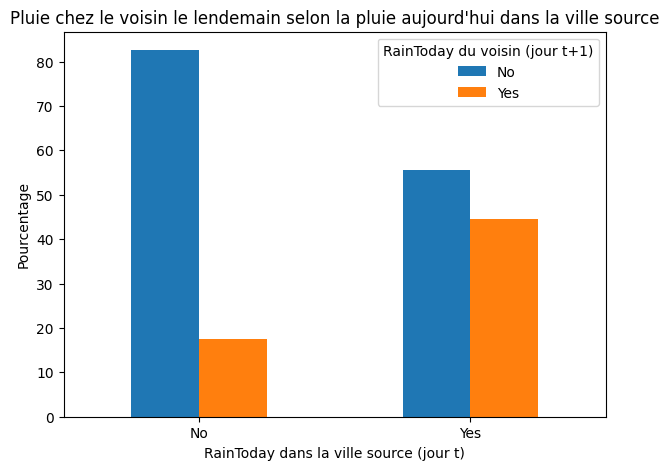

In [45]:
global_nextday_effect.plot(kind="bar", figsize=(7, 5))
plt.title("Pluie chez le voisin le lendemain selon la pluie aujourd'hui dans la ville source")
plt.xlabel("RainToday dans la ville source (jour t)")
plt.ylabel("Pourcentage")
plt.xticks(rotation=0)
plt.legend(title="RainToday du voisin (jour t+1)")
plt.show()

In [46]:
pair_nextday_stats = (
    spatial_nextday_obs
    .groupby(["source_location", "target_location", "distance_km", "source_RainToday"])["target_nextday_RainToday"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .unstack()
    .reset_index()
)

pair_nextday_stats["delta_yes_minus_no"] = pair_nextday_stats["Yes"] - pair_nextday_stats["No"]
pair_nextday_stats = pair_nextday_stats.sort_values("delta_yes_minus_no", ascending=False)

pair_nextday_stats.head(15)

source_RainToday,source_location,target_location,distance_km,No,Yes,delta_yes_minus_no
54,Perth,Witchcliffe,240.887019,21.482730,64.173913,42.691183
2,Albury,MountGinini,178.244099,19.660722,62.218371,42.557649
57,PerthAirport,Witchcliffe,245.458970,22.148210,63.553114,41.404904
89,Witchcliffe,Walpole,183.067752,21.432199,62.831858,41.399659
52,Perth,PearceRAAF,34.681186,10.784314,51.067961,40.283647
55,PerthAirport,PearceRAAF,30.153952,11.297440,50.609756,39.312316
78,WaggaWagga,MountGinini,135.533022,21.309371,59.163347,37.853976
33,MountGambier,Portland,91.842824,25.060241,62.486249,37.426008
53,Perth,PerthAirport,10.034880,11.576763,48.322148,36.745384
56,PerthAirport,Perth,10.034880,12.956130,49.469965,36.513835


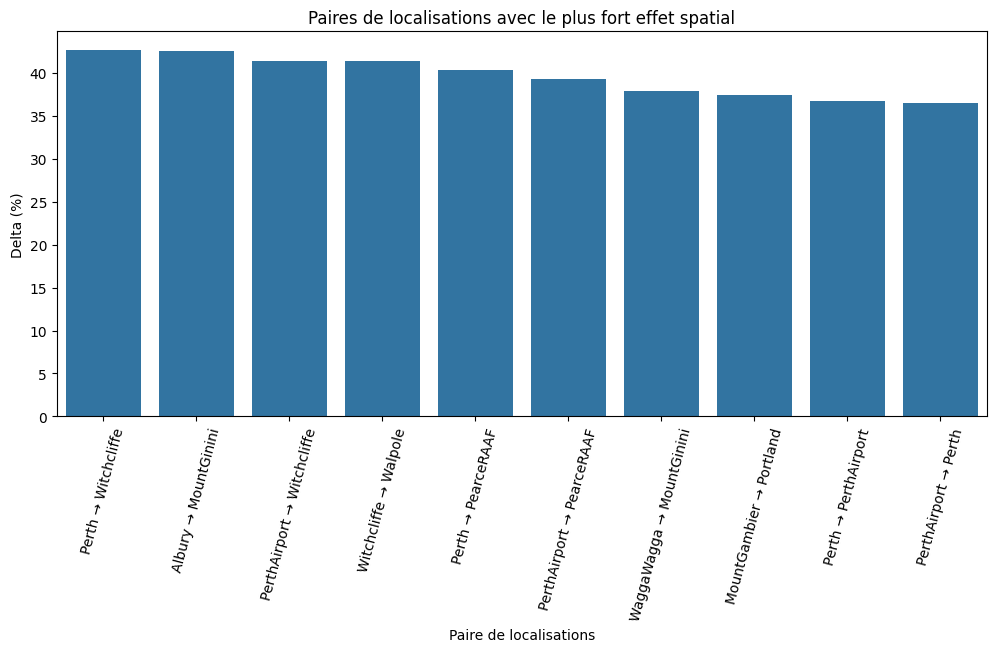

In [47]:
top_pairs = pair_nextday_stats.head(10).copy()
top_pairs["pair"] = top_pairs["source_location"] + " → " + top_pairs["target_location"]

plt.figure(figsize=(12, 5))
sns.barplot(data=top_pairs, x="pair", y="delta_yes_minus_no")
plt.title("Paires de localisations avec le plus fort effet spatial")
plt.xlabel("Paire de localisations")
plt.ylabel("Delta (%)")
plt.xticks(rotation=75)
plt.show()